# Satellite Risk Prediction
## Phase 1: Dataset Acquisition and Inspection

Objective: Understand the ESA satellite conjunction dataset
before preprocessing and machine learning.

In [2]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Setup successful!")

Python version: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Pandas version: 3.0.5
NumPy version: 2.5.1
Setup successful!


In [3]:
PROJECT_DIR = Path.cwd()

print("Current folder:", PROJECT_DIR)
print("\nContents:")

for item in PROJECT_DIR.iterdir():
    print(item.name)

Current folder: C:\Users\vikra\satellite-risk-prediction\notebooks

Contents:
.ipynb_checkpoints
01_dataset_inspection.ipynb


In [4]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
RAW_DIR = PROJECT_DIR / "data" / "raw"

print("Project folder:", PROJECT_DIR)
print("Raw data folder:", RAW_DIR)
print("Does raw folder exist?", RAW_DIR.exists())

print("\nFiles found:")
for file in RAW_DIR.rglob("*"):
    if file.is_file():
        print(file.name)

Project folder: C:\Users\vikra\satellite-risk-prediction
Raw data folder: C:\Users\vikra\satellite-risk-prediction\data\raw
Does raw folder exist? True

Files found:
train_data.csv


In [5]:
csv_files = list(RAW_DIR.rglob("train_data.csv"))

print("Number of CSV files found:", len(csv_files))

for i, file in enumerate(csv_files):
    print(f"{i}: {file.relative_to(RAW_DIR)}")

Number of CSV files found: 1
0: train_data.csv


In [6]:
TRAIN_FILE = csv_files[0]

df = pd.read_csv(TRAIN_FILE)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 162634
Number of columns: 103


In [7]:
df.head()

,event_id,time_to_tca,mission_id,risk,max_risk_estimate,max_risk_scaling,miss_distance,relative_speed,relative_position_r,relative_position_t,...,t_sigma_rdot,c_sigma_rdot,t_sigma_tdot,c_sigma_tdot,t_sigma_ndot,c_sigma_ndot,F10,F3M,SSN,AP
0,0,1.566798,5,-10.204955,-7.834756,8.602101,14923.0,13792.0,453.8,5976.6,...,0.147350,58.272095,0.004092,0.165044,0.002987,0.386462,89.0,83.0,42.0,11.0
1,0,1.207494,5,-10.355758,-7.848937,8.956374,14544.0,13792.0,474.3,5821.2,...,0.059672,57.966413,0.003753,0.164383,0.002933,0.386393,89.0,83.0,42.0,11.0
2,0,0.952193,5,-10.345631,-7.847406,8.932195,14475.0,13792.0,474.6,5796.2,...,0.039258,57.907599,0.003576,0.164352,0.002967,0.386381,89.0,83.0,42.0,11.0
3,0,0.579669,5,-10.337809,-7.845880,8.913444,14579.0,13792.0,472.7,5838.9,...,0.022066,57.993905,0.003298,0.164309,0.002918,0.386400,89.0,83.0,40.0,14.0
4,0,0.257806,5,-10.391260,-7.852942,9.036838,14510.0,13792.0,478.7,5811.1,...,0.015075,57.946717,0.003670,0.164172,0.003220,0.386388,89.0,83.0,40.0,14.0


In [8]:
print(df.columns.tolist())

['event_id', 'time_to_tca', 'mission_id', 'risk', 'max_risk_estimate', 'max_risk_scaling', 'miss_distance', 'relative_speed', 'relative_position_r', 'relative_position_t', 'relative_position_n', 'relative_velocity_r', 'relative_velocity_t', 'relative_velocity_n', 't_time_lastob_start', 't_time_lastob_end', 't_recommended_od_span', 't_actual_od_span', 't_obs_available', 't_obs_used', 't_residuals_accepted', 't_weighted_rms', 't_rcs_estimate', 't_cd_area_over_mass', 't_cr_area_over_mass', 't_sedr', 't_j2k_sma', 't_j2k_ecc', 't_j2k_inc', 't_ct_r', 't_cn_r', 't_cn_t', 't_crdot_r', 't_crdot_t', 't_crdot_n', 't_ctdot_r', 't_ctdot_t', 't_ctdot_n', 't_ctdot_rdot', 't_cndot_r', 't_cndot_t', 't_cndot_n', 't_cndot_rdot', 't_cndot_tdot', 'c_object_type', 'c_time_lastob_start', 'c_time_lastob_end', 'c_recommended_od_span', 'c_actual_od_span', 'c_obs_available', 'c_obs_used', 'c_residuals_accepted', 'c_weighted_rms', 'c_rcs_estimate', 'c_cd_area_over_mass', 'c_cr_area_over_mass', 'c_sedr', 'c_j2k_sm

In [9]:
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])
print("Unique events:", df["event_id"].nunique())
print("Unique missions:", df["mission_id"].nunique())

Total records: 162634
Total columns: 103
Unique events: 13154
Unique missions: 19


In [10]:
important_columns = [
    "event_id",
    "time_to_tca",
    "risk",
    "max_risk_estimate",
    "miss_distance",
    "relative_speed",
    "mahalanobis_distance"
]

df[important_columns].head(10)

,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed,mahalanobis_distance
0,0,1.566798,-10.204955,-7.834756,14923.0,13792.0,129.430951
1,0,1.207494,-10.355758,-7.848937,14544.0,13792.0,271.540424
2,0,0.952193,-10.345631,-7.847406,14475.0,13792.0,347.899292
3,0,0.579669,-10.337809,-7.845880,14579.0,13792.0,435.376626
4,0,0.257806,-10.391260,-7.852942,14510.0,13792.0,469.178802
5,1,6.530455,-7.561299,-7.254301,2392.0,3434.0,4.183398
6,1,5.561646,-9.315693,-7.468904,3587.0,3434.0,7.267719
7,1,5.226504,-7.422508,-7.051001,7882.0,3434.0,11.197928
8,1,3.570013,-9.248105,-7.327533,26899.0,3434.0,62.058087
9,2,6.983474,-10.816161,-6.601713,22902.0,14348.0,115.208802


In [11]:
missing_values = df.isnull().sum()

missing_summary = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("Columns containing missing values:", len(missing_summary))

display(missing_summary)

Columns containing missing values: 50


c_rcs_estimate           52841
c_crdot_r                 9241
c_cndot_n                 9241
c_cndot_rdot              9241
c_cndot_tdot              9241
c_sigma_rdot              9241
c_sigma_ndot              9241
c_sigma_tdot              9241
c_cndot_t                 9241
c_cndot_r                 9241
c_crdot_t                 9241
c_crdot_n                 9241
c_ctdot_r                 9241
c_ctdot_t                 9241
c_ctdot_n                 9241
c_ctdot_rdot              9241
t_crdot_r                 9230
t_crdot_t                 9230
t_sigma_ndot              9230
t_sigma_tdot              9230
t_sigma_rdot              9230
t_ctdot_n                 9230
t_ctdot_t                 9230
t_ctdot_r                 9230
t_cndot_rdot              9230
t_cndot_tdot              9230
t_cndot_t                 9230
t_cndot_r                 9230
t_ctdot_rdot              9230
t_cndot_n                 9230
t_crdot_n                 9230
F3M                       6822
AP      

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 162634 entries, 0 to 162633
Columns: 103 entries, event_id to AP
dtypes: float64(98), int64(4), str(1)
memory usage: 128.8 MB


In [13]:
records_per_event = df.groupby("event_id").size()

print("Minimum records per event:", records_per_event.min())
print("Maximum records per event:", records_per_event.max())
print("Average records per event:", round(records_per_event.mean(), 2))

display(records_per_event.describe())

Minimum records per event: 1
Maximum records per event: 23
Average records per event: 12.36


count    13154.000000
mean        12.363844
std          7.512551
min          1.000000
25%          5.000000
50%         13.000000
75%         20.000000
max         23.000000
dtype: float64

In [14]:
print("Risk statistics:")
display(df["risk"].describe())

print("\nTime-to-TCA statistics:")
display(df["time_to_tca"].describe())

print("\nMax risk estimate statistics:")
display(df["max_risk_estimate"].describe())

Risk statistics:


count    162634.000000
mean        -19.340603
std          10.011641
min         -30.000000
25%         -30.000000
50%         -17.870632
75%          -9.173294
max          -1.442854
Name: risk, dtype: float64


Time-to-TCA statistics:


count    162634.000000
mean          3.350190
std           2.013114
min          -0.149808
25%           1.588082
50%           3.297624
75%           5.083665
max           6.993832
Name: time_to_tca, dtype: float64


Max risk estimate statistics:


count    162634.000000
mean         -6.282332
std           1.012544
min          -9.814175
25%          -7.005199
50%          -6.326610
75%          -5.620559
max          -1.082442
Name: max_risk_estimate, dtype: float64

In [15]:
event_id = 0

event_df = df[df["event_id"] == event_id].copy()

event_df = event_df.sort_values(
    "time_to_tca",
    ascending=False
)

display(
    event_df[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed"
        ]
    ]
)

,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
0,0,1.566798,-10.204955,-7.834756,14923.0,13792.0
1,0,1.207494,-10.355758,-7.848937,14544.0,13792.0
2,0,0.952193,-10.345631,-7.847406,14475.0,13792.0
3,0,0.579669,-10.337809,-7.845880,14579.0,13792.0
4,0,0.257806,-10.391260,-7.852942,14510.0,13792.0


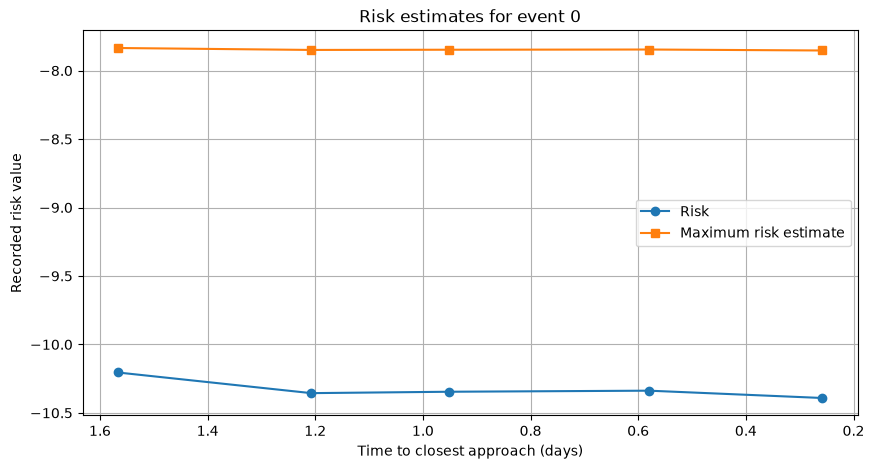

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    event_df["time_to_tca"],
    event_df["risk"],
    marker="o",
    label="Risk"
)

plt.plot(
    event_df["time_to_tca"],
    event_df["max_risk_estimate"],
    marker="s",
    label="Maximum risk estimate"
)

plt.xlabel("Time to closest approach (days)")
plt.ylabel("Recorded risk value")
plt.title("Risk estimates for event 0")
plt.gca().invert_xaxis()
plt.grid(True)
plt.legend()
plt.show()

Events with only one record: 225
Events with multiple records: 12929


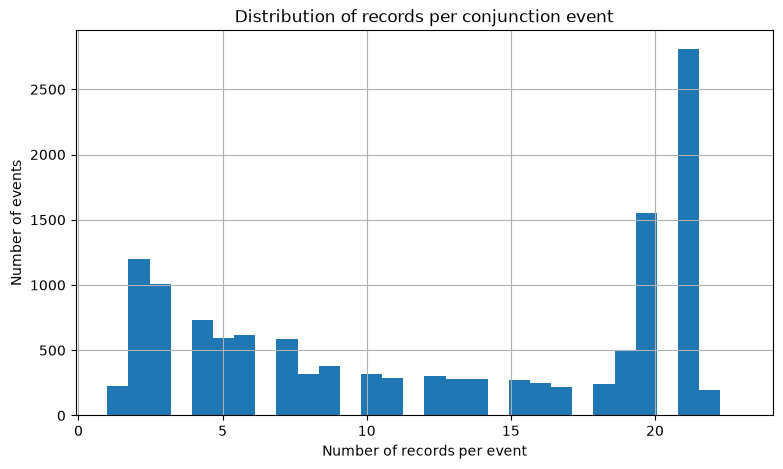

In [17]:
records_per_event = df.groupby("event_id").size()

print("Events with only one record:", (records_per_event == 1).sum())
print("Events with multiple records:", (records_per_event > 1).sum())

plt.figure(figsize=(9, 5))
plt.hist(records_per_event, bins=30)
plt.xlabel("Number of records per event")
plt.ylabel("Number of events")
plt.title("Distribution of records per conjunction event")
plt.grid(True)
plt.show()

In [18]:
print("Records at or after TCA:",
      (df["time_to_tca"] <= 0).sum())

print("Records with risk >= -6:",
      (df["risk"] >= -6).sum())

print("Unique events with risk >= -6:",
      df.loc[df["risk"] >= -6, "event_id"].nunique())

print("\nMinimum time to TCA:", df["time_to_tca"].min())
print("Maximum time to TCA:", df["time_to_tca"].max())

Records at or after TCA: 391
Records with risk >= -6: 10183
Unique events with risk >= -6: 1975

Minimum time to TCA: -0.1498081018518518
Maximum time to TCA: 6.993832407407408


In [19]:
event_id = 1

event_df = df[df["event_id"] == event_id].copy()
event_df = event_df.sort_values("time_to_tca", ascending=False)

display(
    event_df[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed"
        ]
    ]
)

,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
5,1,6.530455,-7.561299,-7.254301,2392.0,3434.0
6,1,5.561646,-9.315693,-7.468904,3587.0,3434.0
7,1,5.226504,-7.422508,-7.051001,7882.0,3434.0
8,1,3.570013,-9.248105,-7.327533,26899.0,3434.0


In [20]:
df_sorted = df.sort_values(
    ["event_id", "time_to_tca"],
    ascending=[True, False]
)

final_records = df_sorted.groupby("event_id").tail(1).copy()

print("Total events:", final_records["event_id"].nunique())

print("Events with final risk >= -6:",
      (final_records["risk"] >= -6).sum())

print("Percentage with final risk >= -6:",
      round((final_records["risk"] >= -6).mean() * 100, 2), "%")

Total events: 13154
Events with final risk >= -6: 365
Percentage with final risk >= -6: 2.77 %


In [21]:
display(
    final_records[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed"
        ]
    ].head(10)
)

,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
4,0,0.257806,-10.391260,-7.852942,14510.0,13792.0
8,1,3.570013,-9.248105,-7.327533,26899.0,3434.0
28,2,0.401947,-30.000000,-7.449283,18708.0,14347.0
49,3,0.283061,-30.000000,-8.439735,23861.0,13574.0
58,4,0.273166,-27.650917,-7.819587,23080.0,12093.0
78,5,0.084142,-30.000000,-5.238523,329.0,2001.0
99,6,0.040905,-30.000000,-5.552222,10905.0,10027.0
106,7,0.613721,-30.000000,-7.351835,31985.0,12410.0
126,8,0.314986,-18.693361,-6.105186,4643.0,12218.0
146,9,0.005807,-14.544394,-7.049392,29824.0,14072.0


In [22]:
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (162634, 103)
Working dataset: (162634, 103)


In [23]:
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing event IDs:", df_clean["event_id"].isna().sum())

numeric_df = df_clean.select_dtypes(include="number")

print(
    "Infinite numeric values:",
    np.isinf(numeric_df.to_numpy()).sum()
)

print("Missing risk values:", df_clean["risk"].isna().sum())

Duplicate rows: 0
Missing event IDs: 0
Infinite numeric values: 0
Missing risk values: 0


In [24]:
missing_summary = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": df_clean.isna().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percent", ascending=False)

display(missing_summary.round(2))

,missing_count,missing_percent
c_rcs_estimate,52841,32.49
c_crdot_r,9241,5.68
c_cndot_n,9241,5.68
c_cndot_rdot,9241,5.68
c_cndot_tdot,9241,5.68
c_sigma_rdot,9241,5.68
c_sigma_ndot,9241,5.68
c_sigma_tdot,9241,5.68
c_cndot_t,9241,5.68
c_cndot_r,9241,5.68


In [25]:
print("Records with risk = -30:",
      (df_clean["risk"] == -30).sum())

print("Records with risk >= -6:",
      (df_clean["risk"] >= -6).sum())

print("Minimum time to TCA:",
      df_clean["time_to_tca"].min())

print("Maximum time to TCA:",
      df_clean["time_to_tca"].max())

Records with risk = -30: 67240
Records with risk >= -6: 10183
Minimum time to TCA: -0.1498081018518518
Maximum time to TCA: 6.993832407407408


In [26]:
early_records = df_clean[
    df_clean["time_to_tca"] >= 2
].copy()

print("Eligible early records:", len(early_records))
print("Events with eligible records:",
      early_records["event_id"].nunique())

Eligible early records: 111939
Events with eligible records: 11942


In [27]:
# Sort each event's records from largest to smallest time before TCA
df_sorted = df_clean.sort_values(
    ["event_id", "time_to_tca"],
    ascending=[True, False]
)

# Select the last available record for each event
final_records = df_sorted.groupby("event_id").tail(1).copy()

# Create one target row per event
targets = final_records[
    ["event_id", "risk"]
].rename(columns={"risk": "final_risk"})

# Create a binary label for high-risk events
targets["high_risk"] = (
    targets["final_risk"] >= -6
).astype("int8")

print("Number of events:", len(targets))
print("\nFinal risk summary:")
display(targets["final_risk"].describe())

print("\nHigh-risk label counts:")
display(targets["high_risk"].value_counts())

Number of events: 13154

Final risk summary:


count    13154.000000
mean       -23.296024
std          9.459063
min        -30.000000
25%        -30.000000
50%        -30.000000
75%        -13.937141
max         -1.684660
Name: final_risk, dtype: float64


High-risk label counts:


high_risk
0    12789
1      365
Name: count, dtype: int64

In [28]:
print("Target rows:", len(targets))
print("Unique event IDs:", targets["event_id"].nunique())
print("Duplicate event IDs:", targets["event_id"].duplicated().sum())
print("Missing final risk:", targets["final_risk"].isna().sum())

display(targets.head(10))

Target rows: 13154
Unique event IDs: 13154
Duplicate event IDs: 0
Missing final risk: 0


,event_id,final_risk,high_risk
4,0,-10.391260,0
8,1,-9.248105,0
28,2,-30.000000,0
49,3,-30.000000,0
58,4,-27.650917,0
78,5,-30.000000,0
99,6,-30.000000,0
106,7,-30.000000,0
126,8,-18.693361,0
146,9,-14.544394,0


In [29]:
# Count each class
risk_counts = targets["high_risk"].value_counts().sort_index()

print("Low-risk events (0):", risk_counts.get(0, 0))
print("High-risk events (1):", risk_counts.get(1, 0))

print("\nClass percentages:")
display(
    (targets["high_risk"].value_counts(normalize=True) * 100)
    .rename("percentage")
    .round(2)
)

Low-risk events (0): 12789
High-risk events (1): 365

Class percentages:


high_risk
0    97.23
1     2.77
Name: percentage, dtype: float64

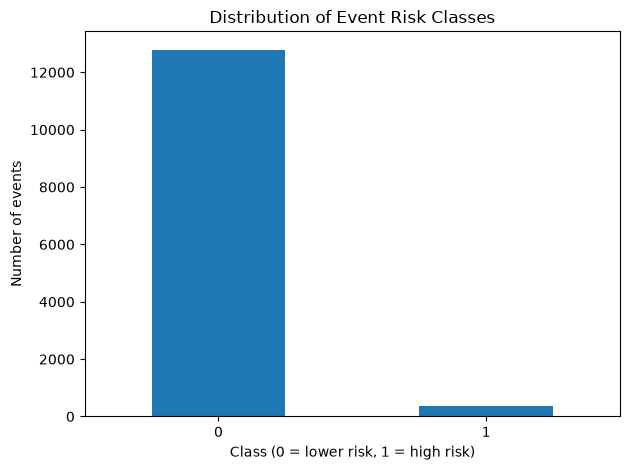

In [30]:
targets["high_risk"].value_counts().sort_index().plot(
    kind="bar",
    xlabel="Class (0 = lower risk, 1 = high risk)",
    ylabel="Number of events",
    title="Distribution of Event Risk Classes",
    rot=0
)

plt.tight_layout()
plt.show()

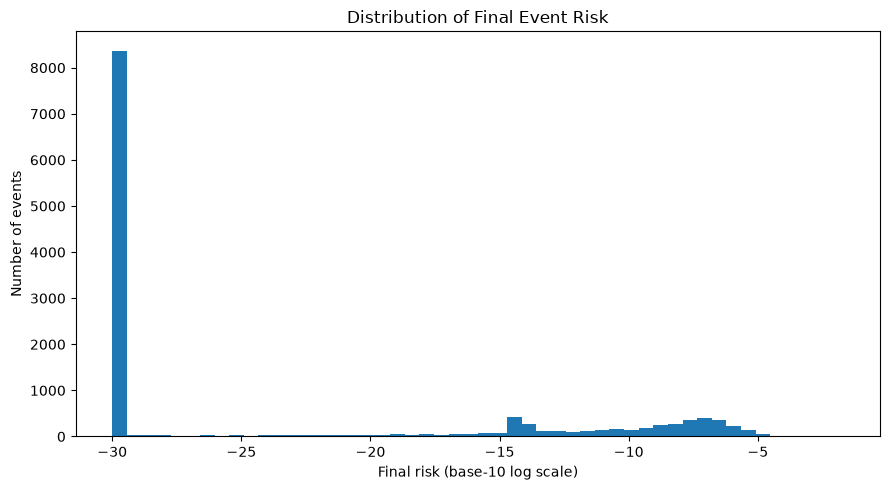

In [31]:
plt.figure(figsize=(9, 5))

plt.hist(targets["final_risk"], bins=50)

plt.xlabel("Final risk (base-10 log scale)")
plt.ylabel("Number of events")
plt.title("Distribution of Final Event Risk")

plt.tight_layout()
plt.show()

In [32]:
print("Early records:", len(early_records))
print("Events represented:", early_records["event_id"].nunique())

print(
    "Records earlier than the 2-day cutoff:",
    (early_records["time_to_tca"] < 2).sum()
)

display(
    early_records[
        ["event_id", "time_to_tca", "risk",
         "max_risk_estimate", "miss_distance", "relative_speed"]
    ].head(10)
)

Early records: 111939
Events represented: 11942
Records earlier than the 2-day cutoff: 0


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
5,1,6.530455,-7.561299,-7.254301,2392.0,3434.0
6,1,5.561646,-9.315693,-7.468904,3587.0,3434.0
7,1,5.226504,-7.422508,-7.051001,7882.0,3434.0
8,1,3.570013,-9.248105,-7.327533,26899.0,3434.0
9,2,6.983474,-10.816161,-6.601713,22902.0,14348.0
10,2,6.691611,-10.850473,-6.603452,22966.0,14348.0
11,2,6.269979,-30.000000,-6.217958,18785.0,14347.0
12,2,6.042352,-30.000000,-6.271078,18842.0,14347.0
13,2,5.711716,-30.000000,-6.277448,19015.0,14347.0
14,2,5.377642,-30.000000,-6.278272,19137.0,14347.0


In [33]:
print("Total early records:", len(early_records))

print(
    "Unique events with early records:",
    early_records["event_id"].nunique()
)

print(
    "Records with time_to_tca below 2 days:",
    (early_records["time_to_tca"] < 2).sum()
)

print(
    "Records with missing risk:",
    early_records["risk"].isna().sum()
)

display(
    early_records[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed"
        ]
    ].head(10)
)

Total early records: 111939
Unique events with early records: 11942
Records with time_to_tca below 2 days: 0
Records with missing risk: 0


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
5,1,6.530455,-7.561299,-7.254301,2392.0,3434.0
6,1,5.561646,-9.315693,-7.468904,3587.0,3434.0
7,1,5.226504,-7.422508,-7.051001,7882.0,3434.0
8,1,3.570013,-9.248105,-7.327533,26899.0,3434.0
9,2,6.983474,-10.816161,-6.601713,22902.0,14348.0
10,2,6.691611,-10.850473,-6.603452,22966.0,14348.0
11,2,6.269979,-30.000000,-6.217958,18785.0,14347.0
12,2,6.042352,-30.000000,-6.271078,18842.0,14347.0
13,2,5.711716,-30.000000,-6.277448,19015.0,14347.0
14,2,5.377642,-30.000000,-6.278272,19137.0,14347.0


In [34]:
print("Total early records:", len(early_records))

print(
    "Unique events with early records:",
    early_records["event_id"].nunique()
)

print(
    "Records with time_to_tca below 2 days:",
    (early_records["time_to_tca"] < 2).sum()
)

print(
    "Records with missing risk:",
    early_records["risk"].isna().sum()
)

display(
    early_records[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed"
        ]
    ].head(10)
)

Total early records: 111939
Unique events with early records: 11942
Records with time_to_tca below 2 days: 0
Records with missing risk: 0


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
5,1,6.530455,-7.561299,-7.254301,2392.0,3434.0
6,1,5.561646,-9.315693,-7.468904,3587.0,3434.0
7,1,5.226504,-7.422508,-7.051001,7882.0,3434.0
8,1,3.570013,-9.248105,-7.327533,26899.0,3434.0
9,2,6.983474,-10.816161,-6.601713,22902.0,14348.0
10,2,6.691611,-10.850473,-6.603452,22966.0,14348.0
11,2,6.269979,-30.000000,-6.217958,18785.0,14347.0
12,2,6.042352,-30.000000,-6.271078,18842.0,14347.0
13,2,5.711716,-30.000000,-6.277448,19015.0,14347.0
14,2,5.377642,-30.000000,-6.278272,19137.0,14347.0


In [35]:
# Sort eligible records by event and time before TCA
early_sorted = early_records.sort_values(
    ["event_id", "time_to_tca"],
    ascending=[True, False]
)

# Select one early observation per event
event_features = (
    early_sorted
    .groupby("event_id")
    .head(1)
    .copy()
    .reset_index(drop=True)
)

print("Feature rows:", len(event_features))
print("Unique events:", event_features["event_id"].nunique())

display(
    event_features[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed"
        ]
    ].head(10)
)

Feature rows: 11942
Unique events: 11942


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed
0,1,6.530455,-7.561299,-7.254301,2392.0,3434.0
1,2,6.983474,-10.816161,-6.601713,22902.0,14348.0
2,3,6.950088,-9.568315,-7.057793,29654.0,13574.0
3,4,4.966244,-7.870632,-6.800245,31612.0,12093.0
4,5,6.790114,-6.189767,-5.558148,424.0,2001.0
5,6,6.733984,-12.156892,-4.753994,10574.0,10027.0
6,7,6.535121,-13.050269,-7.187421,16335.0,12410.0
7,8,6.552403,-6.077586,-5.992679,6501.0,12219.0
8,9,6.718595,-14.523748,-7.051783,29962.0,14072.0
9,10,3.759978,-14.517841,-8.185752,36205.0,10813.0


In [36]:
model_data = event_features.merge(
    targets,
    on="event_id",
    how="inner",
    validate="one_to_one"
)

print("Model dataset shape:", model_data.shape)
print("Missing final targets:", model_data["final_risk"].isna().sum())

display(
    model_data[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "miss_distance",
            "relative_speed",
            "final_risk",
            "high_risk"
        ]
    ].head(10)
)

Model dataset shape: (11942, 105)
Missing final targets: 0


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed,final_risk,high_risk
0,1,6.530455,-7.561299,-7.254301,2392.0,3434.0,-9.248105,0
1,2,6.983474,-10.816161,-6.601713,22902.0,14348.0,-30.000000,0
2,3,6.950088,-9.568315,-7.057793,29654.0,13574.0,-30.000000,0
3,4,4.966244,-7.870632,-6.800245,31612.0,12093.0,-27.650917,0
4,5,6.790114,-6.189767,-5.558148,424.0,2001.0,-30.000000,0
5,6,6.733984,-12.156892,-4.753994,10574.0,10027.0,-30.000000,0
6,7,6.535121,-13.050269,-7.187421,16335.0,12410.0,-30.000000,0
7,8,6.552403,-6.077586,-5.992679,6501.0,12219.0,-18.693361,0
8,9,6.718595,-14.523748,-7.051783,29962.0,14072.0,-14.544394,0
9,10,3.759978,-14.517841,-8.185752,36205.0,10813.0,-30.000000,0


In [37]:
excluded_columns = [
    "event_id",
    "final_risk",
    "high_risk"
]

X = model_data.drop(columns=excluded_columns)
y = model_data["high_risk"]

print("Number of candidate features:", X.shape[1])
print("Number of samples:", X.shape[0])
print("\nCategorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nMissing values in candidate features:")
print(X.isna().sum().sort_values(ascending=False).head(15))

Number of candidate features: 102
Number of samples: 11942

Categorical columns:
['c_object_type']

Missing values in candidate features:
c_rcs_estimate    4050
c_ctdot_n         1520
c_ctdot_r         1520
c_crdot_n         1520
c_crdot_t         1520
c_ctdot_t         1520
c_cndot_t         1520
c_cndot_n         1520
c_cndot_rdot      1520
c_cndot_tdot      1520
c_sigma_tdot      1520
c_sigma_ndot      1520
c_sigma_rdot      1520
c_crdot_r         1520
c_cndot_r         1520
dtype: int64


C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\1759390318.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include=["object", "category"]).columns.tolist())


In [38]:
# Display all columns in our model dataset
print("Total columns:", len(model_data.columns))

display(
    pd.DataFrame({
        "column": model_data.columns,
        "dtype": model_data.dtypes.values,
        "missing_count": model_data.isna().sum().values,
        "missing_percent": (
            model_data.isna().mean().values * 100
        ).round(2)
    }).sort_values("missing_percent", ascending=False)
)

Total columns: 105


,column,dtype,missing_count,missing_percent
53,c_rcs_estimate,float64,4050,33.91
71,c_cndot_t,float64,1520,12.73
72,c_cndot_n,float64,1520,12.73
70,c_cndot_r,float64,1520,12.73
69,c_ctdot_rdot,float64,1520,12.73
...,...,...,...,...
77,t_h_apo,float64,0,0.00
89,t_sigma_t,float64,0,0.00
91,t_sigma_n,float64,0,0.00
103,final_risk,float64,0,0.00


In [39]:
# Target variable
y = model_data["high_risk"]

# Columns that must NOT be used as input features
columns_to_drop = [
    "event_id",
    "final_risk",
    "high_risk"
]

# Create feature dataset
X = model_data.drop(columns=columns_to_drop)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:")
print(X.select_dtypes(include="number").columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

Feature matrix shape: (11942, 102)
Target shape: (11942,)

Numerical features:
['time_to_tca', 'mission_id', 'risk', 'max_risk_estimate', 'max_risk_scaling', 'miss_distance', 'relative_speed', 'relative_position_r', 'relative_position_t', 'relative_position_n', 'relative_velocity_r', 'relative_velocity_t', 'relative_velocity_n', 't_time_lastob_start', 't_time_lastob_end', 't_recommended_od_span', 't_actual_od_span', 't_obs_available', 't_obs_used', 't_residuals_accepted', 't_weighted_rms', 't_rcs_estimate', 't_cd_area_over_mass', 't_cr_area_over_mass', 't_sedr', 't_j2k_sma', 't_j2k_ecc', 't_j2k_inc', 't_ct_r', 't_cn_r', 't_cn_t', 't_crdot_r', 't_crdot_t', 't_crdot_n', 't_ctdot_r', 't_ctdot_t', 't_ctdot_n', 't_ctdot_rdot', 't_cndot_r', 't_cndot_t', 't_cndot_n', 't_cndot_rdot', 't_cndot_tdot', 'c_time_lastob_start', 'c_time_lastob_end', 'c_recommended_od_span', 'c_actual_od_span', 'c_obs_available', 'c_obs_used', 'c_residuals_accepted', 'c_weighted_rms', 'c_rcs_estimate', 'c_cd_area_over

C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\3976828144.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include=["object", "category"]).columns.tolist())


In [40]:
missing_features = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_percent": X.isna().mean() * 100
})

missing_features = missing_features[
    missing_features["missing_count"] > 0
].sort_values("missing_percent", ascending=False)

display(missing_features.round(2))

,missing_count,missing_percent
c_rcs_estimate,4050,33.91
c_crdot_r,1520,12.73
c_cndot_n,1520,12.73
c_cndot_rdot,1520,12.73
c_cndot_tdot,1520,12.73
c_sigma_rdot,1520,12.73
c_sigma_ndot,1520,12.73
c_sigma_tdot,1520,12.73
c_cndot_t,1520,12.73
c_cndot_r,1520,12.73


In [41]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (9553, 102)
Testing features: (2389, 102)

Training target distribution:
high_risk
0    9295
1     258
Name: count, dtype: int64
high_risk
0    97.3
1     2.7
Name: proportion, dtype: float64

Testing target distribution:
high_risk
0    2324
1      65
Name: count, dtype: int64
high_risk
0    97.28
1     2.72
Name: proportion, dtype: float64


In [42]:
# Analyze missing values in training data only
missing_train = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_percent": X_train.isna().mean() * 100
})

missing_train = missing_train[
    missing_train["missing_count"] > 0
].sort_values("missing_percent", ascending=False)

display(missing_train.round(2))

,missing_count,missing_percent
c_rcs_estimate,3238,33.90
c_crdot_r,1222,12.79
c_cndot_n,1222,12.79
c_cndot_rdot,1222,12.79
c_cndot_tdot,1222,12.79
c_sigma_rdot,1222,12.79
c_sigma_ndot,1222,12.79
c_sigma_tdot,1222,12.79
c_cndot_t,1222,12.79
c_cndot_r,1222,12.79


In [43]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the training rules
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessed training shape:", X_train_processed.shape)
print("Preprocessed testing shape:", X_test_processed.shape)

C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\977635739.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


Numerical features: 101
Categorical features: 1

Preprocessed training shape: (9553, 106)
Preprocessed testing shape: (2389, 106)


In [44]:
print("Training data:")
print("Shape:", X_train_processed.shape)
print("Missing values:", np.isnan(X_train_processed.toarray()).sum()
      if hasattr(X_train_processed, "toarray")
      else np.isnan(X_train_processed).sum())

print("\nTesting data:")
print("Shape:", X_test_processed.shape)

print("\nTraining labels:", len(y_train))
print("Testing labels:", len(y_test))

Training data:
Shape: (9553, 106)
Missing values: 0

Testing data:
Shape: (2389, 106)

Training labels: 9553
Testing labels: 2389


In [45]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Create baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the model
baseline_model.fit(X_train_processed, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test_processed)

# Evaluate
print("Baseline Accuracy:", accuracy_score(y_test, baseline_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        baseline_predictions,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.972791963164504

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      2324
           1       0.00      0.00      0.00        65

    accuracy                           0.97      2389
   macro avg       0.49      0.50      0.49      2389
weighted avg       0.95      0.97      0.96      2389


Confusion Matrix:
[[2324    0]
 [  65    0]]


In [46]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [47]:
# Predict classes
lr_predictions = lr_model.predict(X_test_processed)

# Predict probabilities
lr_probabilities = lr_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(lr_predictions[:10])

print("\nFirst 10 high-risk probabilities:")
print(lr_probabilities[:10])

First 10 predictions:
[0 0 0 0 1 0 0 0 0 1]

First 10 high-risk probabilities:
[3.82594200e-02 2.79330049e-03 4.09436983e-01 4.10082179e-04
 9.28561317e-01 1.02782813e-01 5.10445607e-02 2.99999524e-01
 1.31697703e-01 7.60406765e-01]


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, lr_predictions))

print("Precision:",
      precision_score(y_test, lr_predictions, zero_division=0))

print("Recall:",
      recall_score(y_test, lr_predictions, zero_division=0))

print("F1 Score:",
      f1_score(y_test, lr_predictions, zero_division=0))

print("F2 Score:",
      fbeta_score(y_test, lr_predictions, beta=2, zero_division=0))

print("PR-AUC (Average Precision):",
      average_precision_score(y_test, lr_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.7685223943072416
Precision: 0.07785467128027682
Recall: 0.6923076923076923
F1 Score: 0.13996889580093314
F2 Score: 0.2684964200477327
PR-AUC (Average Precision): 0.10312034682319259

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.77      0.87      2324
           1       0.08      0.69      0.14        65

    accuracy                           0.77      2389
   macro avg       0.53      0.73      0.50      2389
weighted avg       0.96      0.77      0.85      2389


Confusion Matrix:
[[1791  533]
 [  20   45]]


In [49]:
import numpy as np

print("Total test events:", len(y_test))

print(
    "Predicted high-risk events:",
    np.sum(lr_predictions == 1)
)

print(
    "Actual high-risk events:",
    np.sum(y_test == 1)
)

print(
    "Predicted high-risk percentage:",
    round(np.mean(lr_predictions == 1) * 100, 2),
    "%"
)

Total test events: 2389
Predicted high-risk events: 578
Actual high-risk events: 65
Predicted high-risk percentage: 24.19 %


In [50]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [51]:
# Generate predictions
rf_predictions = rf_model.predict(X_test_processed)

# Generate high-risk probabilities
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(rf_predictions[:10])

print("\nFirst 10 high-risk probabilities:")
print(rf_probabilities[:10])

First 10 predictions:
[0 0 0 0 1 0 0 0 0 0]

First 10 high-risk probabilities:
[0.    0.    0.195 0.015 0.815 0.005 0.015 0.035 0.005 0.37 ]


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

print("RANDOM FOREST RESULTS")

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, zero_division=0))
print("Recall:", recall_score(y_test, rf_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, rf_predictions, zero_division=0))
print("F2 Score:", fbeta_score(y_test, rf_predictions, beta=2, zero_division=0))
print("PR-AUC (Average Precision):", average_precision_score(y_test, rf_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

RANDOM FOREST RESULTS
Accuracy: 0.9732105483465885
Precision: 0.5161290322580645
Recall: 0.24615384615384617
F1 Score: 0.3333333333333333
F2 Score: 0.27491408934707906
PR-AUC (Average Precision): 0.34731712328377795

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2324
           1       0.52      0.25      0.33        65

    accuracy                           0.97      2389
   macro avg       0.75      0.62      0.66      2389
weighted avg       0.97      0.97      0.97      2389


Confusion Matrix:
[[2309   15]
 [  49   16]]


In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
importance = rf_model.feature_importances_

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
print(feature_importance.head(20))

                      Feature  Importance
2                   num__risk    0.164007
4       num__max_risk_scaling    0.098957
3      num__max_risk_estimate    0.084190
5          num__miss_distance    0.025242
82  num__mahalanobis_distance    0.024717
21        num__t_rcs_estimate    0.023999
86             num__c_sigma_r    0.019253
88             num__c_sigma_t    0.016285
7    num__relative_position_r    0.015004
27             num__t_j2k_inc    0.013515
96          num__c_sigma_ndot    0.012581
25             num__t_j2k_sma    0.012350
92          num__c_sigma_rdot    0.011465
73                num__t_span    0.011264
54                num__c_sedr    0.010740
75               num__t_h_apo    0.010711
94          num__c_sigma_tdot    0.010271
22   num__t_cd_area_over_mass    0.009569
58                num__c_ct_r    0.008701
8    num__relative_position_t    0.008650


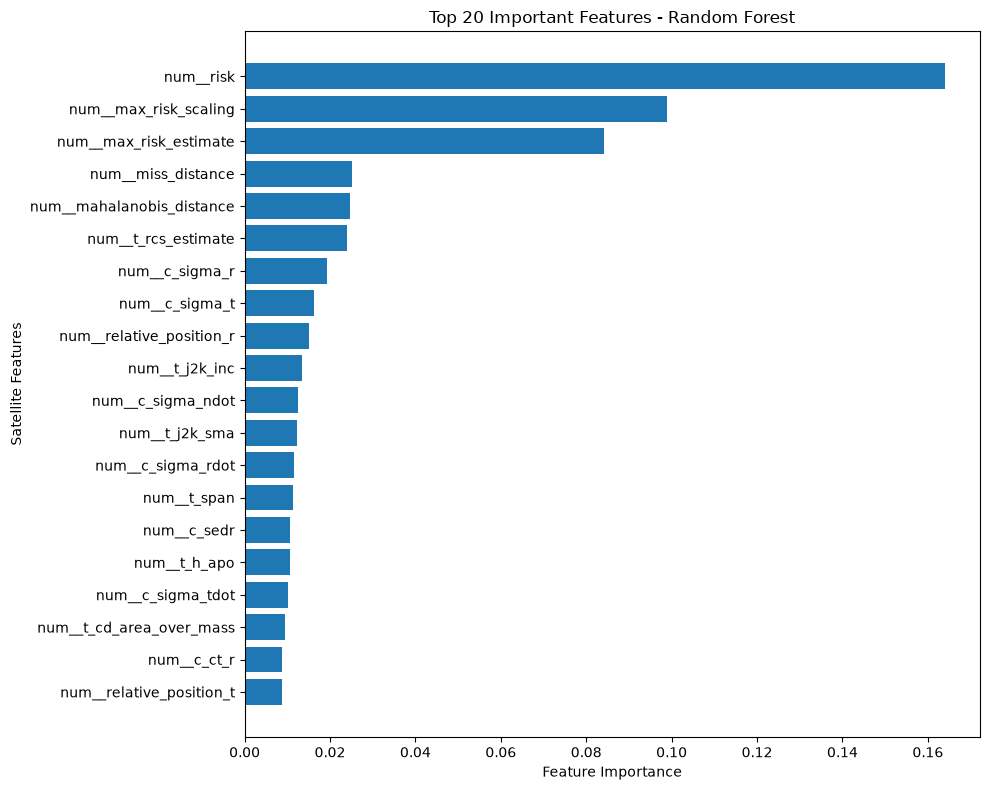

In [54]:
plt.figure(figsize=(10, 8))

top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Satellite Features")
plt.title("Top 20 Important Features - Random Forest")

plt.tight_layout()
plt.show()

In [55]:
# Identify all risk-related columns
risk_columns = [
    col for col in df.columns
    if "risk" in col.lower()
]

print("Risk-related columns:")
for col in risk_columns:
    print(col)

# Display sample observations
print("\nFirst 15 observations:")
print(
    df_clean[
        [
            "event_id",
            "time_to_tca",
            "risk",
            "max_risk_estimate",
            "max_risk_scaling"
        ]
    ].head(15).to_string(index=False)
)

Risk-related columns:
risk
max_risk_estimate
max_risk_scaling

First 15 observations:
 event_id  time_to_tca       risk  max_risk_estimate  max_risk_scaling
        0     1.566798 -10.204955          -7.834756          8.602101
        0     1.207494 -10.355758          -7.848937          8.956374
        0     0.952193 -10.345631          -7.847406          8.932195
        0     0.579669 -10.337809          -7.845880          8.913444
        0     0.257806 -10.391260          -7.852942          9.036838
        1     6.530455  -7.561299          -7.254301          2.746782
        1     5.561646  -9.315693          -7.468904          7.223137
        1     5.226504  -7.422508          -7.051001          2.956639
        1     3.570013  -9.248105          -7.327533          7.425994
        2     6.983474 -10.816161          -6.601713         13.293159
        2     6.691611 -10.850473          -6.603452         13.374242
        2     6.269979 -30.000000          -6.217958        42

In [56]:
# Select CDMs that are at least 2 days before TCA
eligible_records = df_clean[
    df_clean["time_to_tca"] >= 2
].copy()

# Select the closest eligible CDM to TCA for each event
event_features_corrected = (
    eligible_records
    .sort_values(
        ["event_id", "time_to_tca"],
        ascending=[True, True]
    )
    .groupby("event_id")
    .head(1)
    .copy()
)

print("Corrected feature dataset shape:")
print(event_features_corrected.shape)

print("\nNumber of unique events:")
print(event_features_corrected["event_id"].nunique())

print("\nTime to TCA summary:")
print(event_features_corrected["time_to_tca"].describe())

print("\nFirst 10 selected observations:")
print(
    event_features_corrected[
        ["event_id", "time_to_tca", "risk"]
    ].head(10)
)

Corrected feature dataset shape:
(11942, 103)

Number of unique events:
11942

Time to TCA summary:
count    11942.000000
mean         2.846878
std          1.206974
min          2.000014
25%          2.124713
50%          2.252246
75%          2.958525
max          6.951860
Name: time_to_tca, dtype: float64

First 10 selected observations:
     event_id  time_to_tca       risk
8           1     3.570013  -9.248105
22          2     2.340627 -30.000000
43          3     2.278941 -30.000000
52          4     3.066467 -30.000000
72          5     2.103772 -13.100070
93          6     2.040187 -30.000000
104         7     2.531723 -30.000000
120         8     2.285275 -18.845576
141         9     2.033839 -14.593460
152        10     2.131981 -30.000000


In [57]:
# Merge corrected features with the target labels
model_data_corrected = event_features_corrected.merge(
    targets,
    on="event_id",
    how="inner",
    validate="one_to_one"
)

# Separate features and target
X_corrected = model_data_corrected.drop(
    columns=["event_id", "final_risk", "high_risk"]
)

y_corrected = model_data_corrected["high_risk"]

print("Corrected model dataset:", model_data_corrected.shape)

print("\nTarget distribution:")
print(y_corrected.value_counts())

print("\nTarget percentages:")
print(
    (y_corrected.value_counts(normalize=True) * 100).round(2)
)

Corrected model dataset: (11942, 105)

Target distribution:
high_risk
0    11619
1      323
Name: count, dtype: int64

Target percentages:
high_risk
0    97.3
1     2.7
Name: proportion, dtype: float64


In [58]:
from sklearn.model_selection import train_test_split

X_train_corrected, X_test_corrected, y_train_corrected, y_test_corrected = train_test_split(
    X_corrected,
    y_corrected,
    test_size=0.20,
    random_state=42,
    stratify=y_corrected
)

print("Training features:", X_train_corrected.shape)
print("Testing features:", X_test_corrected.shape)

print("\nTraining target distribution:")
print(y_train_corrected.value_counts())

print("\nTesting target distribution:")
print(y_test_corrected.value_counts())

Training features: (9553, 102)
Testing features: (2389, 102)

Training target distribution:
high_risk
0    9295
1     258
Name: count, dtype: int64

Testing target distribution:
high_risk
0    2324
1      65
Name: count, dtype: int64


In [59]:
# Identify numerical columns
numeric_features_corrected = (
    X_train_corrected
    .select_dtypes(include=["number"])
    .columns.tolist()
)

# Identify categorical columns
categorical_features_corrected = (
    X_train_corrected
    .select_dtypes(include=["object", "category", "bool"])
    .columns.tolist()
)

print("Number of numerical features:",
      len(numeric_features_corrected))

print("Number of categorical features:",
      len(categorical_features_corrected))

print("\nCategorical features:")
print(categorical_features_corrected)

Number of numerical features: 101
Number of categorical features: 1

Categorical features:
['c_object_type']


C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\3159963378.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(include=["object", "category", "bool"])


In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline_corrected = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline_corrected = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor_corrected = ColumnTransformer([
    ("num", numeric_pipeline_corrected, numeric_features_corrected),
    ("cat", categorical_pipeline_corrected, categorical_features_corrected)
])

print("Corrected preprocessing pipeline created!")

Corrected preprocessing pipeline created!


In [61]:
# Fit only on training data
X_train_processed_corrected = (
    preprocessor_corrected.fit_transform(X_train_corrected)
)

# Transform testing data using the fitted pipeline
X_test_processed_corrected = (
    preprocessor_corrected.transform(X_test_corrected)
)

print("Training processed shape:",
      X_train_processed_corrected.shape)

print("Testing processed shape:",
      X_test_processed_corrected.shape)

Training processed shape: (9553, 106)
Testing processed shape: (2389, 106)


In [62]:
import numpy as np

if hasattr(X_train_processed_corrected, "toarray"):
    train_array = X_train_processed_corrected.toarray()
    test_array = X_test_processed_corrected.toarray()
else:
    train_array = X_train_processed_corrected
    test_array = X_test_processed_corrected

print("Missing values in training:",
      np.isnan(train_array).sum())

print("Missing values in testing:",
      np.isnan(test_array).sum())

Missing values in training: 0
Missing values in testing: 0


In [63]:
from sklearn.linear_model import LogisticRegression

lr_model_corrected = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

lr_model_corrected.fit(
    X_train_processed_corrected,
    y_train_corrected
)

print("Corrected Logistic Regression training completed!")

Corrected Logistic Regression training completed!


In [64]:
from sklearn.ensemble import RandomForestClassifier

rf_model_corrected = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model_corrected.fit(
    X_train_processed_corrected,
    y_train_corrected
)

print("Corrected Random Forest training completed!")

Corrected Random Forest training completed!


In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    average_precision_score,
    confusion_matrix
)

def evaluate_model(model, X_test, y_test, model_name):

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print("\n", model_name)
    print("-" * 40)

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_test, predictions, zero_division=0))
    print("F2 Score:", fbeta_score(y_test, predictions, beta=2, zero_division=0))
    print("PR-AUC:", average_precision_score(y_test, probabilities))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

evaluate_model(
    lr_model_corrected,
    X_test_processed_corrected,
    y_test_corrected,
    "CORRECTED LOGISTIC REGRESSION"
)

evaluate_model(
    rf_model_corrected,
    X_test_processed_corrected,
    y_test_corrected,
    "CORRECTED RANDOM FOREST"
)


 CORRECTED LOGISTIC REGRESSION
----------------------------------------
Accuracy: 0.9049811636668061
Precision: 0.20863309352517986
Recall: 0.8923076923076924
F1 Score: 0.33819241982507287
F2 Score: 0.5390334572490706
PR-AUC: 0.29272341494852233

Confusion Matrix:
[[2104  220]
 [   7   58]]

 CORRECTED RANDOM FOREST
----------------------------------------
Accuracy: 0.9840937630807869
Precision: 0.684931506849315
Recall: 0.7692307692307693
F1 Score: 0.7246376811594203
F2 Score: 0.7507507507507507
PR-AUC: 0.8058417836301595

Confusion Matrix:
[[2301   23]
 [  15   50]]


In [66]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance_corrected = (
    rf_model_corrected.feature_importances_
)

# Get feature names
feature_names_corrected = (
    preprocessor_corrected.get_feature_names_out()
)

# Create feature importance DataFrame
feature_importance_corrected = pd.DataFrame({
    "Feature": feature_names_corrected,
    "Importance": importance_corrected
})

# Sort by importance
feature_importance_corrected = (
    feature_importance_corrected
    .sort_values(
        by="Importance",
        ascending=False
    )
)

# Display top 20 features
print(feature_importance_corrected.head(20).to_string(index=False))


                  Feature  Importance
                num__risk    0.273341
    num__max_risk_scaling    0.155244
   num__max_risk_estimate    0.151659
num__mahalanobis_distance    0.038257
         num__time_to_tca    0.025249
           num__c_sigma_t    0.023716
       num__miss_distance    0.023592
           num__c_sigma_r    0.018197
      num__t_rcs_estimate    0.014256
        num__c_sigma_rdot    0.013220
 num__relative_position_r    0.009603
           num__t_j2k_inc    0.009576
        num__c_sigma_ndot    0.009464
              num__t_span    0.008809
        num__c_sigma_tdot    0.007154
 num__relative_position_n    0.005595
           num__t_j2k_sma    0.005520
             num__t_h_apo    0.005328
 num__relative_position_t    0.005009
           num__c_sigma_n    0.004999


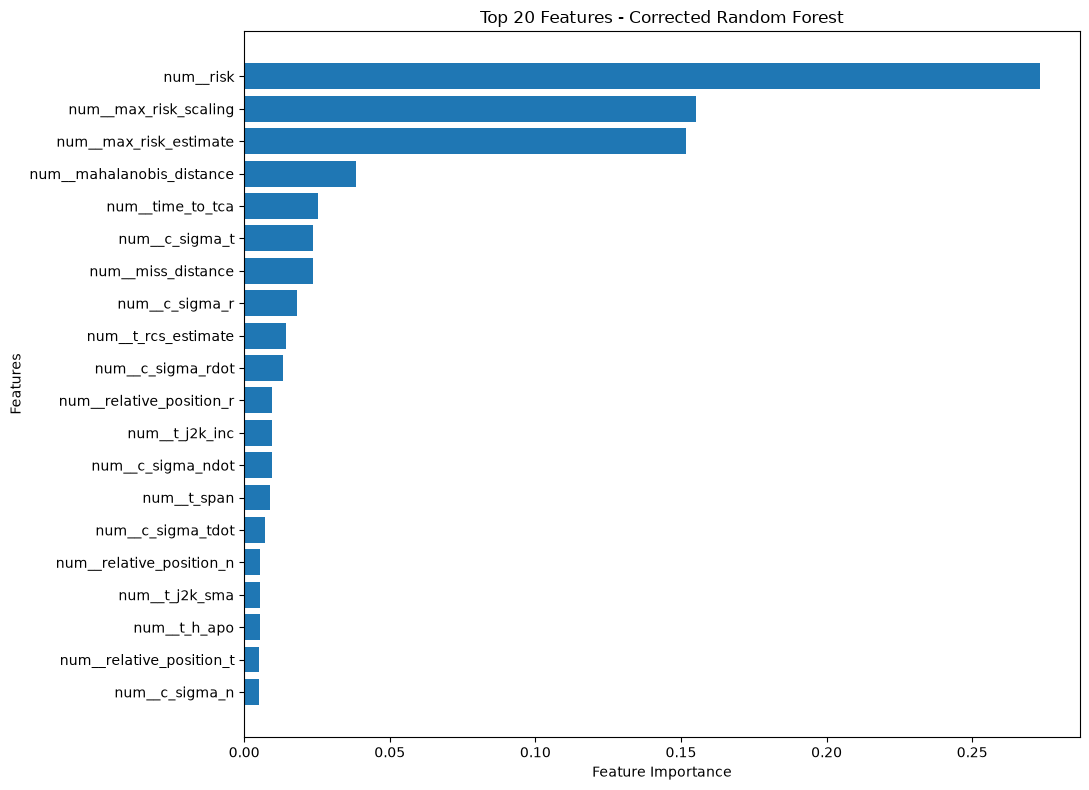

In [67]:
plt.figure(figsize=(11, 8))

top_features = (
    feature_importance_corrected
    .head(20)
    .sort_values(by="Importance")
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 Features - Corrected Random Forest")

plt.tight_layout()
plt.show()

In [68]:
# Remove risk-related features
columns_to_remove = [
    "risk",
    "max_risk_estimate",
    "max_risk_scaling"
]

X_train_no_risk = X_train_corrected.drop(
    columns=columns_to_remove
)

X_test_no_risk = X_test_corrected.drop(
    columns=columns_to_remove
)

print("Training shape:", X_train_no_risk.shape)
print("Testing shape:", X_test_no_risk.shape)

Training shape: (9553, 99)
Testing shape: (2389, 99)


In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_no_risk = X_train_no_risk.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_no_risk = X_train_no_risk.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline_no_risk = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_no_risk = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_no_risk = ColumnTransformer([
    ("num", numeric_pipeline_no_risk, numeric_no_risk),
    ("cat", categorical_pipeline_no_risk, categorical_no_risk)
])

X_train_no_risk_processed = preprocessor_no_risk.fit_transform(
    X_train_no_risk
)

X_test_no_risk_processed = preprocessor_no_risk.transform(
    X_test_no_risk
)

print("Preprocessing completed!")
print("Training:", X_train_no_risk_processed.shape)
print("Testing:", X_test_no_risk_processed.shape)

C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\2800789140.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_no_risk = X_train_no_risk.select_dtypes(


Preprocessing completed!
Training: (9553, 103)
Testing: (2389, 103)


In [70]:
from sklearn.ensemble import RandomForestClassifier

rf_no_risk = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_no_risk.fit(
    X_train_no_risk_processed,
    y_train_corrected
)

print("Random Forest without risk features trained!")

Random Forest without risk features trained!


In [71]:
evaluate_model(
    rf_no_risk,
    X_test_no_risk_processed,
    y_test_corrected,
    "RANDOM FOREST WITHOUT RISK FEATURES"
)


 RANDOM FOREST WITHOUT RISK FEATURES
----------------------------------------
Accuracy: 0.9748848890749268
Precision: 0.631578947368421
Recall: 0.18461538461538463
F1 Score: 0.2857142857142857
F2 Score: 0.21505376344086022
PR-AUC: 0.40177566242945156

Confusion Matrix:
[[2317    7]
 [  53   12]]


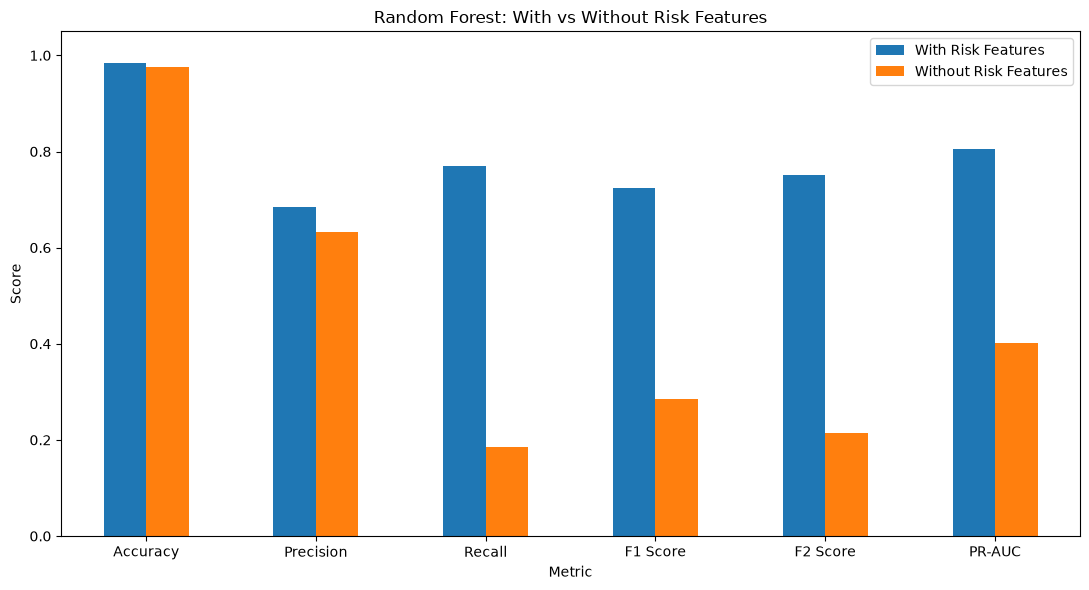

In [72]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "F2 Score",
        "PR-AUC"
    ],
    "With Risk Features": [
        0.9841,
        0.6849,
        0.7692,
        0.7246,
        0.7508,
        0.8058
    ],
    "Without Risk Features": [
        0.9749,
        0.6316,
        0.1846,
        0.2857,
        0.2151,
        0.4018
    ]
})

comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Random Forest: With vs Without Risk Features")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [73]:
from sklearn.model_selection import train_test_split

# Split the existing training data into training and validation sets
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X_train_corrected,
    y_train_corrected,
    test_size=0.20,
    random_state=42,
    stratify=y_train_corrected
)

print("Final training dataset:", X_train_final.shape)
print("Validation dataset:", X_val_final.shape)

print("\nTraining class distribution:")
print(y_train_final.value_counts())

print("\nValidation class distribution:")
print(y_val_final.value_counts())

Final training dataset: (7642, 102)
Validation dataset: (1911, 102)

Training class distribution:
high_risk
0    7436
1     206
Name: count, dtype: int64

Validation class distribution:
high_risk
0    1859
1      52
Name: count, dtype: int64


In [74]:
numeric_features_final = (
    X_train_final
    .select_dtypes(include=["number"])
    .columns.tolist()
)

categorical_features_final = (
    X_train_final
    .select_dtypes(include=["object", "category", "bool"])
    .columns.tolist()
)

print("Numerical features:", len(numeric_features_final))
print("Categorical features:", len(categorical_features_final))
print("Categorical columns:", categorical_features_final)

Numerical features: 101
Categorical features: 1
Categorical columns: ['c_object_type']


C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\73986357.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  .select_dtypes(include=["object", "category", "bool"])


In [75]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_final = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_final = ColumnTransformer([
    ("num", numeric_pipeline_final, numeric_features_final),
    ("cat", categorical_pipeline_final, categorical_features_final)
])

print("Final preprocessing pipeline created!")

Final preprocessing pipeline created!


In [76]:
# Fit on training data only
X_train_final_processed = preprocessor_final.fit_transform(
    X_train_final
)

# Transform validation and test data
X_val_final_processed = preprocessor_final.transform(
    X_val_final
)

X_test_final_processed = preprocessor_final.transform(
    X_test_corrected
)

print("Training shape:", X_train_final_processed.shape)
print("Validation shape:", X_val_final_processed.shape)
print("Testing shape:", X_test_final_processed.shape)

Training shape: (7642, 106)
Validation shape: (1911, 106)
Testing shape: (2389, 106)


In [77]:
import numpy as np

def count_missing(data):
    if hasattr(data, "toarray"):
        data = data.toarray()
    return np.isnan(data).sum()

print("Training missing values:",
      count_missing(X_train_final_processed))

print("Validation missing values:",
      count_missing(X_val_final_processed))

print("Testing missing values:",
      count_missing(X_test_final_processed))

Training missing values: 0
Validation missing values: 0
Testing missing values: 0


In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

In [79]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_final),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [80]:
param_distributions = {
    "classifier__n_estimators": [200, 300, 400, 500],

    "classifier__max_depth": [None, 10, 15, 20, 30],

    "classifier__min_samples_split": [2, 5, 10],

    "classifier__min_samples_leaf": [1, 2, 4],

    "classifier__max_features": ["sqrt", 0.5, 0.8],

    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

In [81]:
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Randomized Search configured!")

Randomized Search configured!


In [82]:
random_search.fit(
    X_train_final,
    y_train_final
)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Hyperparameter tuning completed!


In [83]:
print("Model dataset shape:", model_data.shape)

print("Duplicate event IDs:",
      model_data["event_id"].duplicated().sum())

print("Missing values:",
      model_data.isna().sum().sum())

numeric_features = model_data.select_dtypes(include="number")

print("Infinite values:",
      np.isinf(numeric_features.to_numpy()).sum())

Model dataset shape: (11942, 105)
Duplicate event IDs: 0
Missing values: 51724
Infinite values: 0


In [84]:
# Exclude identifiers and target columns
excluded_columns = [
    "event_id",
    "final_risk",
    "high_risk"
]

feature_data = model_data.drop(
    columns=excluded_columns
)

# Calculate missing-value statistics
missing_summary = pd.DataFrame({
    "missing_count": feature_data.isna().sum(),
    "missing_percentage": feature_data.isna().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_summary.round(2))

,missing_count,missing_percentage
c_rcs_estimate,4050,33.91
c_crdot_r,1520,12.73
c_cndot_n,1520,12.73
c_cndot_rdot,1520,12.73
c_cndot_tdot,1520,12.73
c_sigma_rdot,1520,12.73
c_sigma_ndot,1520,12.73
c_sigma_tdot,1520,12.73
c_cndot_t,1520,12.73
c_cndot_r,1520,12.73


In [85]:
categorical_columns = feature_data.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

for col in categorical_columns:
    print("\nColumn:", col)
    display(feature_data[col].value_counts(dropna=False))

Categorical columns: ['c_object_type']

Column: c_object_type


C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\33729166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = feature_data.select_dtypes(


c_object_type
DEBRIS         6546
UNKNOWN        3866
PAYLOAD        1357
ROCKET BODY     157
TBA              16
Name: count, dtype: int64

In [86]:
print("Total candidate features:", feature_data.shape[1])

print("Features with missing values:",
      feature_data.isna().any().sum())

print("Features without missing values:",
      feature_data.notna().all().sum())

Total candidate features: 102
Features with missing values: 50
Features without missing values: 52


In [87]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = model_data.drop(
    columns=["event_id", "final_risk", "high_risk"]
)

y = model_data["high_risk"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (9553, 102)
Testing features: (2389, 102)

Training target distribution:
high_risk
0    9295
1     258
Name: count, dtype: int64

Testing target distribution:
high_risk
0    2324
1      65
Name: count, dtype: int64


In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify column types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

Numerical features: 101
Categorical features: ['c_object_type']


C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\131940618.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify column types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

Numerical features: 101
Categorical features: ['c_object_type']


C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\131940618.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [90]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [91]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [92]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [93]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (9553, 106)
Processed testing shape: (2389, 106)


In [94]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix,
    classification_report
)

In [95]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

In [96]:
logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [97]:
y_pred = logistic_model.predict(X_test_processed)

print("Predictions generated!")

Predictions generated!


In [98]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))

print("F2 Score:",
      fbeta_score(y_test, y_pred, beta=2, zero_division=0))

Accuracy: 0.7685223943072416
Precision: 0.07785467128027682
Recall: 0.6923076923076923
F1 Score: 0.13996889580093314
F2 Score: 0.2684964200477327


In [99]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Low Risk", "High Risk"],
    zero_division=0
))

              precision    recall  f1-score   support

    Low Risk       0.99      0.77      0.87      2324
   High Risk       0.08      0.69      0.14        65

    accuracy                           0.77      2389
   macro avg       0.53      0.73      0.50      2389
weighted avg       0.96      0.77      0.85      2389



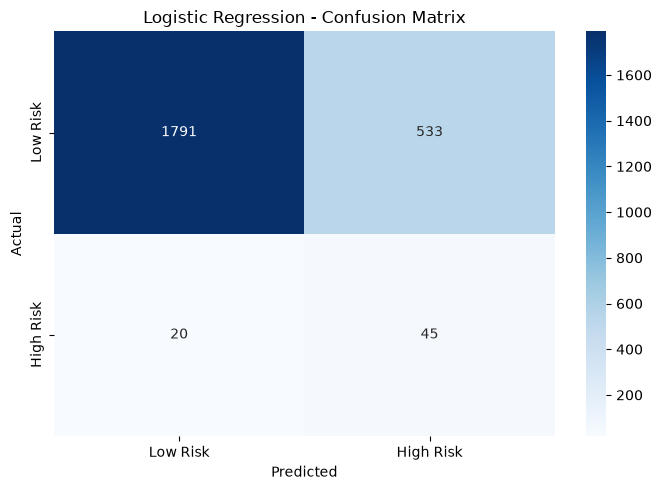

[[1791  533]
 [  20   45]]


In [100]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()

print(cm)

In [101]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Sub-training:", X_subtrain.shape)
print("Validation:", X_val.shape)

print("\nSub-training classes:")
print(y_subtrain.value_counts())

print("\nValidation classes:")
print(y_val.value_counts())

Sub-training: (7642, 102)
Validation: (1911, 102)

Sub-training classes:
high_risk
0    7436
1     206
Name: count, dtype: int64

Validation classes:
high_risk
0    1859
1      52
Name: count, dtype: int64


In [102]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [103]:
# Identify feature types using sub-training data
numeric_features = X_subtrain.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_subtrain.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_rf, numeric_features),
        ("cat", categorical_transformer_rf, categorical_features)
    ]
)

C:\Users\vikra\AppData\Local\Temp\ipykernel_28428\2634360663.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_subtrain.select_dtypes(


In [104]:
rf_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

In [105]:
rf_model.fit(X_subtrain, y_subtrain)

print("Random Forest training completed!")

C:\Users\vikra\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\_array_api.py:976: RuntimeWarning: overflow encountered in cast
  array = numpy.asarray(array, order=order, dtype=dtype)


ValueError: Input X contains infinity or a value too large for dtype('float32').

In [106]:
import numpy as np
import pandas as pd

# Select numerical columns
numeric_data = X_subtrain.select_dtypes(include="number")

# Maximum absolute value in each column
max_values = numeric_data.abs().max().sort_values(
    ascending=False
)

display(max_values.head(20))

t_position_covariance_det    6.732289e+46
c_position_covariance_det    6.732289e+46
t_sigma_r                    6.378136e+07
c_sigma_r                    6.378136e+07
t_sigma_n                    6.378136e+07
c_sigma_t                    6.378136e+07
t_sigma_t                    6.378136e+07
c_sigma_n                    6.378136e+07
max_risk_scaling             1.909428e+07
c_sigma_ndot                 7.905366e+04
t_sigma_ndot                 7.905366e+04
c_sigma_tdot                 7.905366e+04
t_sigma_tdot                 7.905366e+04
c_sigma_rdot                 7.905366e+04
t_sigma_rdot                 7.905366e+04
miss_distance                6.720600e+04
relative_position_t          6.130400e+04
relative_position_n          5.097660e+04
c_h_apo                      4.178257e+04
c_j2k_sma                    2.747271e+04
dtype: float64

In [107]:
float32_limit = np.finfo(np.float32).max

problem_columns = []

for col in numeric_data.columns:

    inf_count = np.isinf(numeric_data[col]).sum()

    too_large_count = (
        numeric_data[col].abs() > float32_limit
    ).sum()

    if inf_count > 0 or too_large_count > 0:
        problem_columns.append({
            "column": col,
            "infinite_values": inf_count,
            "too_large_values": too_large_count,
            "maximum_absolute_value": numeric_data[col].abs().max()
        })

problem_df = pd.DataFrame(problem_columns)

display(problem_df)

,column,infinite_values,too_large_values,maximum_absolute_value
0,t_position_covariance_det,0,217,6.732289e+46
1,c_position_covariance_det,0,194,6.732289e+46


In [108]:
for col in max_values.head(10).index:

    print("\nColumn:", col)

    display(
        X_subtrain[col]
        .sort_values(ascending=False)
        .head(5)
    )


Column: t_position_covariance_det


6162     6.732289e+46
11305    6.732289e+46
11479    6.732289e+46
1838     6.732289e+46
8070     6.732289e+46
Name: t_position_covariance_det, dtype: float64


Column: c_position_covariance_det


4225    6.732289e+46
5765    6.732289e+46
3425    6.732289e+46
2330    6.732289e+46
8611    6.732289e+46
Name: c_position_covariance_det, dtype: float64


Column: t_sigma_r


11916    63781363.0
4246     63781363.0
7098     63781363.0
3347     63781363.0
488      63781363.0
Name: t_sigma_r, dtype: float64

... (10 outputs left out)


Column: max_risk_scaling


2808    1.909428e+07
9053    5.560905e+06
9949    2.596922e+06
7979    1.200704e+06
7006    9.848321e+05
Name: max_risk_scaling, dtype: float64


Column: c_sigma_ndot


1581     79053.661498
463      79053.661498
5131     79053.661498
9489     79053.661498
10951    79053.661498
Name: c_sigma_ndot, dtype: float64

In [109]:
columns_to_check = [
    "t_position_covariance_det",
    "c_position_covariance_det"
]

for col in columns_to_check:
    print("\nColumn:", col)

    print("Minimum:", X_subtrain[col].min())
    print("Maximum:", X_subtrain[col].max())

    print("Zero values:", (X_subtrain[col] == 0).sum())

    print("Negative values:", (X_subtrain[col] < 0).sum())

    print("Unique values:", X_subtrain[col].nunique())

    print("Values equal to maximum:",
          (X_subtrain[col] == X_subtrain[col].max()).sum())

    display(X_subtrain[col].describe())


Column: t_position_covariance_det
Minimum: 114.95935181121578
Maximum: 6.732289373602052e+46
Zero values: 0
Negative values: 0
Unique values: 7427
Values equal to maximum: 144


count    7.642000e+03
mean     1.911681e+45
std      1.118310e+46
min      1.149594e+02
25%      2.717908e+06
50%      2.043317e+07
75%      3.061639e+08
max      6.732289e+46
Name: t_position_covariance_det, dtype: float64


Column: c_position_covariance_det
Minimum: -8.175632684813821e+18
Maximum: 6.732289373602052e+46
Zero values: 4
Negative values: 2
Unique values: 7447
Values equal to maximum: 56


count    7.642000e+03
mean     1.709060e+45
std      1.059022e+46
min     -8.175633e+18
25%      2.792455e+13
50%      3.116976e+15
75%      3.147318e+17
max      6.732289e+46
Name: c_position_covariance_det, dtype: float64

In [110]:
from sklearn.preprocessing import FunctionTransformer
import numpy as np

In [111]:
covariance_features = [
    "t_position_covariance_det",
    "c_position_covariance_det"
]

other_numeric_features = [
    col for col in numeric_features
    if col not in covariance_features
]

In [112]:
covariance_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(
        lambda x: np.sign(x) * np.log10(1 + np.abs(x))
    ))
])

In [113]:
other_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [114]:
categorical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [115]:
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "covariance",
            covariance_transformer,
            covariance_features
        ),
        (
            "numeric",
            other_numeric_transformer,
            other_numeric_features
        ),
        (
            "categorical",
            categorical_transformer_rf,
            categorical_features
        )
    ]
)

In [116]:
rf_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

In [117]:
rf_model.fit(X_subtrain, y_subtrain)

print("Random Forest training completed!")

Random Forest training completed!


In [118]:
y_val_pred = rf_model.predict(X_val)

In [119]:
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Low Risk", "High Risk"],
    zero_division=0
))

print("F2 Score:",
      fbeta_score(y_val, y_val_pred, beta=2, zero_division=0))

              precision    recall  f1-score   support

    Low Risk       0.98      1.00      0.99      1859
   High Risk       1.00      0.10      0.18        52

    accuracy                           0.98      1911
   macro avg       0.99      0.55      0.58      1911
weighted avg       0.98      0.98      0.97      1911

F2 Score: 0.11737089201877934


In [120]:
# Get high-risk probabilities on validation data
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Try different classification thresholds
thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)

    print("Precision:",
          precision_score(y_val, predictions, zero_division=0))

    print("Recall:",
          recall_score(y_val, predictions, zero_division=0))

    print("F2:",
          fbeta_score(y_val, predictions, beta=2, zero_division=0))


Threshold: 0.05
Precision: 0.16236162361623616
Recall: 0.8461538461538461
F2: 0.4592901878914405

Threshold: 0.1
Precision: 0.2532467532467532
Recall: 0.75
F2: 0.5386740331491713

Threshold: 0.15
Precision: 0.308411214953271
Recall: 0.6346153846153846
F2: 0.5238095238095238

Threshold: 0.2
Precision: 0.29333333333333333
Recall: 0.4230769230769231
F2: 0.38869257950530034

Threshold: 0.25
Precision: 0.3469387755102041
Recall: 0.3269230769230769
F2: 0.33073929961089493

Threshold: 0.3
Precision: 0.42857142857142855
Recall: 0.23076923076923078
F2: 0.2542372881355932

Threshold: 0.4
Precision: 0.6428571428571429
Recall: 0.17307692307692307
F2: 0.20270270270270271

Threshold: 0.5
Precision: 1.0
Recall: 0.09615384615384616
F2: 0.11737089201877934


In [121]:
fine_thresholds = np.arange(0.05, 0.151, 0.01)

fine_results = []

for threshold in fine_thresholds:

    predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    fine_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "f2": fbeta_score(
            y_val, predictions, beta=2, zero_division=0
        )
    })

fine_results_df = pd.DataFrame(fine_results)

display(
    fine_results_df.sort_values(
        "f2", ascending=False
    ).round(4)
)

,threshold,precision,recall,f1,f2
7,0.12,0.2923,0.7308,0.4176,0.5621
9,0.14,0.3097,0.6731,0.4242,0.5452
6,0.11,0.2657,0.7308,0.3897,0.5413
5,0.10,0.2532,0.7500,0.3786,0.5387
8,0.13,0.2893,0.6731,0.4046,0.5319
3,0.08,0.2199,0.8077,0.3457,0.5263
10,0.15,0.3084,0.6346,0.4151,0.5238
2,0.07,0.2057,0.8269,0.3295,0.5156
4,0.09,0.2254,0.7500,0.3467,0.5118
1,0.06,0.1830,0.8269,0.2997,0.4853


In [122]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

In [123]:
gb_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    ))
])

In [124]:
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_subtrain
)

print("Sample weights calculated!")

Sample weights calculated!


In [125]:
gb_model.fit(
    X_subtrain,
    y_subtrain,
    classifier__sample_weight=sample_weights
)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [126]:
gb_probabilities = gb_model.predict_proba(X_val)[:, 1]

In [127]:
gb_thresholds = np.arange(0.05, 0.501, 0.01)

gb_results = []

for threshold in gb_thresholds:

    predictions = (
        gb_probabilities >= threshold
    ).astype(int)

    gb_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "f2": fbeta_score(
            y_val, predictions, beta=2, zero_division=0
        )
    })

gb_results_df = pd.DataFrame(gb_results)

display(
    gb_results_df.sort_values(
        "f2", ascending=False
    ).head(10).round(4)
)

,threshold,precision,recall,f1,f2
45,0.50,0.1575,0.8269,0.2646,0.4470
44,0.49,0.1558,0.8269,0.2622,0.4442
43,0.48,0.1547,0.8269,0.2606,0.4424
40,0.45,0.1507,0.8462,0.2558,0.4400
42,0.47,0.1514,0.8269,0.2560,0.4370
39,0.44,0.1477,0.8462,0.2514,0.4348
41,0.46,0.1493,0.8269,0.2529,0.4335
38,0.43,0.1443,0.8462,0.2465,0.4288
37,0.42,0.1420,0.8654,0.2439,0.4286
36,0.41,0.1389,0.8654,0.2394,0.4229


In [128]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


In [129]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   -- ------------------------------------- 2.6/48.9 MB 11.8 MB/s eta 0:00:04
   ----- ---------------------------------- 6.3/48.9 MB 15.2 MB/s eta 0:00:03
   -------- ------------------------------- 11.0/48.9 MB 17.1 MB/s eta 0:00:03
   ------------ --------------------------- 15.7/48.9 MB 18.4 MB/s eta 0:00:02
   ----------------- ---------------------- 21.2/48.9 MB 19.9 MB/s eta 0:00:02
   -------------------- ------------------- 25.2/48.9 MB 19.6 MB/s eta 0:00:02
   ------------------------ --------------- 30.1/48.9 MB 20.0 MB/s eta 0:00:01
   ---------------------------- ----------- 34.9/48.9 MB 21.0 MB/s eta 0:00:01
   ------------------------------- -------- 38.0/48.9 MB 19.9 MB/s eta 0:00:01
   --------------------------------- ------ 41.4/48.9 MB 19.4 MB/s eta 0:00:01
  

In [130]:
from xgboost import XGBClassifier

# Calculate the imbalance ratio
scale_weight = (
    (y_subtrain == 0).sum() /
    (y_subtrain == 1).sum()
)

print("Scale positive weight:", scale_weight)

Scale positive weight: 36.09708737864078


In [131]:
xgb_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [132]:
xgb_model.fit(X_subtrain, y_subtrain)

print("XGBoost training completed!")

XGBoost training completed!


In [133]:
xgb_probabilities = xgb_model.predict_proba(X_val)[:, 1]

In [134]:
xgb_thresholds = np.arange(0.05, 0.501, 0.01)

xgb_results = []

for threshold in xgb_thresholds:

    predictions = (
        xgb_probabilities >= threshold
    ).astype(int)

    xgb_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "f2": fbeta_score(
            y_val, predictions, beta=2, zero_division=0
        )
    })

xgb_results_df = pd.DataFrame(xgb_results)

display(
    xgb_results_df.sort_values(
        "f2", ascending=False
    ).head(10).round(4)
)

,threshold,precision,recall,f1,f2
39,0.44,0.2639,0.7308,0.3878,0.5398
37,0.42,0.2532,0.7500,0.3786,0.5387
36,0.41,0.2500,0.7500,0.3750,0.5357
42,0.47,0.2662,0.7115,0.3874,0.5331
35,0.40,0.2468,0.7500,0.3714,0.5328
34,0.39,0.2438,0.7500,0.3679,0.5299
40,0.45,0.2606,0.7115,0.3814,0.5286
41,0.46,0.2606,0.7115,0.3814,0.5286
38,0.43,0.2500,0.7308,0.3725,0.5278
33,0.38,0.2407,0.7500,0.3645,0.5270


In [135]:
# Refit Logistic Regression on sub-training data
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_subtrain, y_subtrain)

# Validation probabilities
lr_probabilities = lr_model.predict_proba(X_val)[:, 1]

In [136]:
lr_thresholds = np.arange(0.05, 0.501, 0.01)

lr_results = []

for threshold in lr_thresholds:

    predictions = (
        lr_probabilities >= threshold
    ).astype(int)

    lr_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "f2": fbeta_score(
            y_val, predictions, beta=2, zero_division=0
        )
    })

lr_results_df = pd.DataFrame(lr_results)

display(
    lr_results_df.sort_values(
        "f2", ascending=False
    ).head(10).round(4)
)

,threshold,precision,recall,f1,f2
44,0.49,0.0903,0.7692,0.1616,0.3072
45,0.50,0.0911,0.7500,0.1625,0.3066
39,0.44,0.0867,0.8269,0.1569,0.3054
36,0.41,0.0843,0.8654,0.1536,0.3032
40,0.45,0.0866,0.8077,0.1564,0.3030
35,0.40,0.0835,0.8846,0.1526,0.3030
42,0.47,0.0874,0.7885,0.1574,0.3028
38,0.43,0.0848,0.8269,0.1538,0.3007
43,0.48,0.0870,0.7692,0.1562,0.2994
41,0.46,0.0856,0.7885,0.1544,0.2984


In [137]:
n_estimators=300
class_weight="balanced_subsample"
min_samples_leaf=2

In [138]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint

In [139]:
param_distributions = {
    "classifier__n_estimators": [200, 300, 500],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", "log2"]
}

In [140]:
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="fbeta",
    refit=True,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [141]:
from sklearn.metrics import make_scorer

f2_scorer = make_scorer(
    fbeta_score,
    beta=2,
    zero_division=0
)

In [142]:
scoring=f2_scorer

In [143]:
rf_search.fit(X_subtrain, y_subtrain)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F2:")
print(rf_search.best_score_)

InvalidParameterError: The 'scoring' parameter of RandomizedSearchCV must be a str among {'f1_macro', 'jaccard_micro', 'f1_weighted', 'precision_weighted', 'neg_log_loss', 'homogeneity_score', 'explained_variance', 'jaccard', 'mutual_info_score', 'neg_mean_absolute_error', 'roc_auc_ovr_weighted', 'f1_samples', 'positive_likelihood_ratio', 'recall_samples', 'r2', 'v_measure_score', 'accuracy', 'completeness_score', 'top_k_accuracy', 'balanced_accuracy', 'neg_mean_absolute_percentage_error', 'neg_root_mean_squared_log_error', 'recall_weighted', 'neg_max_error', 'f1', 'neg_negative_likelihood_ratio', 'precision', 'roc_auc_ovr', 'adjusted_mutual_info_score', 'jaccard_macro', 'd2_brier_score', 'roc_auc_ovo_weighted', 'neg_brier_score', 'neg_mean_gamma_deviance', 'neg_mean_squared_log_error', 'jaccard_weighted', 'f1_micro', 'neg_mean_squared_error', 'precision_micro', 'average_precision', 'roc_auc', 'neg_root_mean_squared_error', 'recall_macro', 'd2_absolute_error_score', 'jaccard_samples', 

In [144]:
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Create F2 scorer
f2_scorer = make_scorer(
    fbeta_score,
    beta=2,
    zero_division=0
)

# Recreate search with correct scoring
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions,
    n_iter=10,  # Reduced from 20 to save time
    scoring=f2_scorer,
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune
rf_search.fit(X_subtrain, y_subtrain)

print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F2:")
print(rf_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5}

Best cross-validation F2:
0.4710302532633502


In [145]:
import numpy as np
import pandas as pd
import joblib

from sklearn.base import clone
from sklearn.metrics import (
    fbeta_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score
)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# --------------------------------------------------
# 1. GET TUNED RANDOM FOREST
# --------------------------------------------------

rf_best_model = rf_search.best_estimator_
rf_best_probabilities = rf_best_model.predict_proba(X_val)[:, 1]

# --------------------------------------------------
# 2. COLLECT MODEL PREDICTIONS
# --------------------------------------------------

models = {
    "Random Forest": (rf_best_model, rf_best_probabilities),
    "XGBoost": (xgb_model, xgb_probabilities),
    "Gradient Boosting": (gb_model, gb_probabilities),
    "Logistic Regression": (lr_model, lr_probabilities)
}

# --------------------------------------------------
# 3. FIND BEST F2 THRESHOLD FOR EACH MODEL
# --------------------------------------------------

results = []

for name, (model, probabilities) in models.items():

    best_f2 = 0
    best_threshold = 0.5

    for threshold in np.arange(0.01, 0.501, 0.01):

        predictions = (probabilities >= threshold).astype(int)

        score = fbeta_score(
            y_val,
            predictions,
            beta=2,
            zero_division=0
        )

        if score > best_f2:
            best_f2 = score
            best_threshold = threshold

    predictions = (probabilities >= best_threshold).astype(int)

    results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F2 Score": best_f2
    })

results_df = pd.DataFrame(results).sort_values(
    "F2 Score", ascending=False
).reset_index(drop=True)

print("\nVALIDATION MODEL LEADERBOARD")
print(results_df.to_string(index=False))

# --------------------------------------------------
# 4. SELECT WINNER
# --------------------------------------------------

winner_name = results_df.loc[0, "Model"]
best_threshold = float(results_df.loc[0, "Threshold"])
selected_model = models[winner_name][0]

print("\nSelected Model:", winner_name)
print("Selected Threshold:", best_threshold)
print("Validation F2:", round(results_df.loc[0, "F2 Score"], 4))

# --------------------------------------------------
# 5. REFIT WINNER ON COMPLETE TRAINING DATA
# --------------------------------------------------

final_model = clone(selected_model)

if isinstance(
    final_model.named_steps["classifier"],
    GradientBoostingClassifier
):
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )
    final_model.fit(
        X_train,
        y_train,
        classifier__sample_weight=sample_weights
    )
else:
    final_model.fit(X_train, y_train)

# --------------------------------------------------
# 6. FINAL TEST EVALUATION
# --------------------------------------------------

test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("\nFINAL TEST RESULTS")
print("------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, test_predictions), 4))

print("Precision:",
      round(precision_score(y_test, test_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, test_predictions, zero_division=0), 4))

print("F2 Score:",
      round(fbeta_score(y_test, test_predictions, beta=2,
                        zero_division=0), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, test_probabilities), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, test_probabilities), 4))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, test_predictions))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Low Risk", "High Risk"],
    zero_division=0
))

# --------------------------------------------------
# 7. SAVE FINAL MODEL AND THRESHOLD
# --------------------------------------------------

joblib.dump(
    {
        "model": final_model,
        "threshold": best_threshold,
        "model_name": winner_name
    },
    "satellite_risk_model_final.pkl"
)

print("\nFinal model saved successfully!")
print("File: satellite_risk_model_final.pkl")


VALIDATION MODEL LEADERBOARD
              Model  Threshold  Precision   Recall  F2 Score
            XGBoost       0.44   0.263889 0.730769  0.539773
      Random Forest       0.50   0.232558 0.769231  0.526316
  Gradient Boosting       0.50   0.157509 0.826923  0.446985
Logistic Regression       0.49   0.090293 0.769231  0.307220

Selected Model: XGBoost
Selected Threshold: 0.44
Validation F2: 0.5398

FINAL TEST RESULTS
------------------------------
Accuracy: 0.9163
Precision: 0.1973
Recall: 0.6769
F2 Score: 0.4555
PR-AUC: 0.3278
ROC-AUC: 0.9118

CONFUSION MATRIX
[[2145  179]
 [  21   44]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Low Risk       0.99      0.92      0.96      2324
   High Risk       0.20      0.68      0.31        65

    accuracy                           0.92      2389
   macro avg       0.59      0.80      0.63      2389
weighted avg       0.97      0.92      0.94      2389



PicklingError: Can't pickle <function <lambda> at 0x0000028441F27EC0>: it's not found as __main__.<lambda>

In [146]:
import numpy as np
import joblib
import importlib
from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# 1. Create a separate Python module for the transformation
module_code = '''
import numpy as np

def signed_log_transform(X):
    return np.sign(X) * np.log10(1 + np.abs(X))
'''

Path("satellite_transformers.py").write_text(
    module_code,
    encoding="utf-8"
)

import satellite_transformers
importlib.reload(satellite_transformers)

# 2. Rebuild covariance preprocessing without lambda
safe_covariance_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(
        satellite_transformers.signed_log_transform,
        validate=False
    ))
])

safe_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

safe_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 3. Rebuild complete preprocessing pipeline
safe_rf_preprocessor = ColumnTransformer([
    ("covariance", safe_covariance_transformer, covariance_features),
    ("numeric", safe_numeric_transformer, other_numeric_features),
    ("categorical", safe_categorical_transformer, categorical_features)
])

# 4. Rebuild and train selected XGBoost pipeline
final_model = clone(xgb_model)

final_model.set_params(
    preprocessor=safe_rf_preprocessor
)

final_model.fit(X_train, y_train)

# 5. Save final model and threshold
model_artifact = {
    "model": final_model,
    "threshold": best_threshold,
    "model_name": winner_name
}

joblib.dump(
    model_artifact,
    "satellite_risk_model_final.pkl",
    compress=3
)

print("MODEL SAVED SUCCESSFULLY!")
print("Model:", winner_name)
print("Threshold:", best_threshold)
print("File: satellite_risk_model_final.pkl")
print("Transformation module: satellite_transformers.py")

# 6. Verify that the saved model can be loaded
loaded_artifact = joblib.load("satellite_risk_model_final.pkl")

print("\nMODEL LOAD VERIFICATION")
print("Loaded model:", loaded_artifact["model_name"])
print("Loaded threshold:", loaded_artifact["threshold"])

MODEL SAVED SUCCESSFULLY!
Model: XGBoost
Threshold: 0.44
File: satellite_risk_model_final.pkl
Transformation module: satellite_transformers.py

MODEL LOAD VERIFICATION
Loaded model: XGBoost
Loaded threshold: 0.44


In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract the fitted preprocessing pipeline
preprocessor = final_model.named_steps["preprocessor"]

# 2. Extract transformed feature names
feature_names = preprocessor.get_feature_names_out()

# 3. Extract XGBoost feature importance scores
xgb_classifier = final_model.named_steps["classifier"]
importance_scores = xgb_classifier.feature_importances_

# 4. Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# 5. Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# 6. Display top 20 features
print("TOP 20 IMPORTANT FEATURES")
print("=" * 60)

print(
    feature_importance.head(20).to_string(index=False)
)

# 7. Visualize top 20 features
top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Satellite Parameters")
plt.title("Top 20 Features - XGBoost Model")

plt.tight_layout()
plt.show()

# 8. Save complete feature importance results
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("\nFeature importance saved as feature_importance.csv")

AttributeError: Estimator log_transform does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?

Number of feature names: 106
Number of importance scores: 106

TOP 20 IMPORTANT FEATURES
              Feature  Importance
                 risk    0.060147
     max_risk_scaling    0.038908
 c_object_type_DEBRIS    0.027987
               c_sedr    0.026582
    max_risk_estimate    0.020000
    c_time_lastob_end    0.017802
        miss_distance    0.016972
            c_crdot_r    0.016533
  c_time_lastob_start    0.016214
c_recommended_od_span    0.016000
            c_ctdot_t    0.015458
            t_cndot_r    0.014144
            c_sigma_r    0.014127
               t_span    0.012744
            t_crdot_r    0.012603
            c_sigma_t    0.012458
         c_ctdot_rdot    0.012141
               c_ct_r    0.012042
              t_h_per    0.011755
 t_residuals_accepted    0.011399


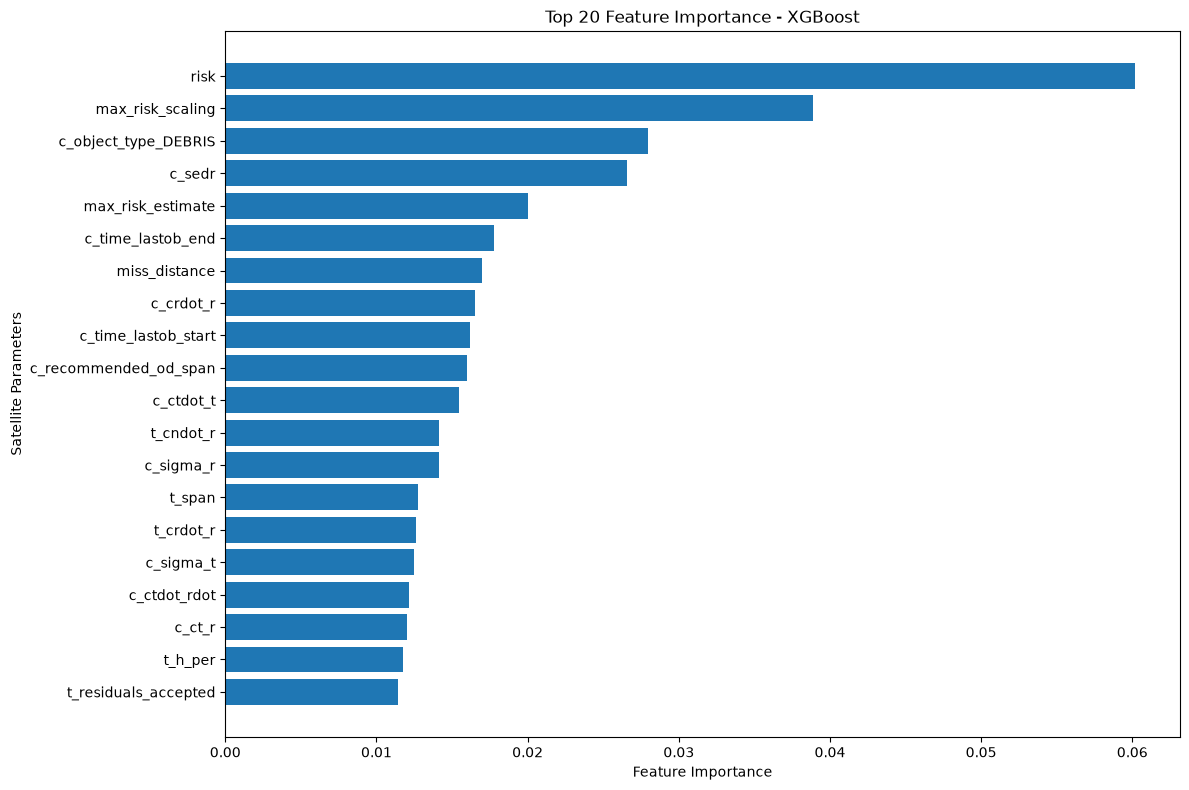


Saved: feature_importance.csv


In [148]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Get fitted preprocessing and XGBoost classifier
preprocessor = final_model.named_steps["preprocessor"]
xgb_classifier = final_model.named_steps["classifier"]

# 2. Generate feature names manually
covariance_names = covariance_features
numeric_names = other_numeric_features

# Get encoded categorical feature names
cat_pipeline = preprocessor.named_transformers_["categorical"]
onehot_encoder = cat_pipeline.named_steps["onehot"]

categorical_names = onehot_encoder.get_feature_names_out(
    categorical_features
).tolist()

# Combine all feature names in transformer order
feature_names = (
    covariance_names +
    numeric_names +
    categorical_names
)

# 3. Extract feature importance
importance_scores = xgb_classifier.feature_importances_

# Verify dimensions
print("Number of feature names:", len(feature_names))
print("Number of importance scores:", len(importance_scores))

if len(feature_names) != len(importance_scores):
    raise ValueError("Feature names and importance scores do not match!")

# 4. Create importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
})

# 5. Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# 6. Display top 20 features
print("\nTOP 20 IMPORTANT FEATURES")
print("=" * 60)
print(feature_importance.head(20).to_string(index=False))

# 7. Plot top 20 features
top_features = feature_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(12, 8))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Satellite Parameters")
plt.title("Top 20 Feature Importance - XGBoost")
plt.tight_layout()
plt.show()

# 8. Save results
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("\nSaved: feature_importance.csv")

In [149]:
import os
import sys
import subprocess
from pathlib import Path

# 1. Install required packages
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "fastapi", "uvicorn", "pandas", "joblib", "xgboost"
])

# 2. Create backend directory
project_path = Path.cwd()
backend_path = project_path / "backend"
backend_path.mkdir(exist_ok=True)

# 3. Verify model files
model_path = project_path / "satellite_risk_model_final.pkl"
transformer_path = project_path / "satellite_transformers.py"

if not model_path.exists():
    raise FileNotFoundError(
        f"Model not found: {model_path}"
    )

if not transformer_path.exists():
    raise FileNotFoundError(
        f"Transformer module not found: {transformer_path}"
    )

# 4. Create FastAPI application
main_code = '''
from pathlib import Path
import sys
import joblib
import pandas as pd

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
from typing import Any

BASE_DIR = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(BASE_DIR))

import satellite_transformers

MODEL_PATH = BASE_DIR / "satellite_risk_model_final.pkl"

artifact = joblib.load(MODEL_PATH)

model = artifact["model"]
THRESHOLD = artifact["threshold"]

# Original model input columns
FEATURE_COLUMNS = list(model.feature_names_in_)

app = FastAPI(
    title="Satellite Conjunction Risk Prediction API",
    description="Machine learning API for early satellite conjunction risk prediction",
    version="1.0.0"
)

class PredictionInput(BaseModel):
    features: dict[str, Any]

@app.get("/")
def home():
    return {
        "message": "Satellite Risk Prediction API is running",
        "model": artifact["model_name"],
        "threshold": THRESHOLD
    }

@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": True
    }

@app.post("/predict")
def predict(data: PredictionInput):

    missing = [
        col for col in FEATURE_COLUMNS
        if col not in data.features
    ]

    if missing:
        raise HTTPException(
            status_code=400,
            detail={
                "message": "Missing required input features",
                "missing_features": missing
            }
        )

    try:
        input_df = pd.DataFrame(
            [[data.features[col] for col in FEATURE_COLUMNS]],
            columns=FEATURE_COLUMNS
        )

        probability = float(
            model.predict_proba(input_df)[0][1]
        )

        prediction = int(probability >= THRESHOLD)

        return {
            "predicted_class": prediction,
            "classification": (
                "HIGH RISK" if prediction == 1 else "LOW RISK"
            ),
            "high_risk_probability": round(probability, 6),
            "threshold": THRESHOLD,
            "model": artifact["model_name"]
        }

    except Exception as error:
        raise HTTPException(
            status_code=500,
            detail=str(error)
        )
'''

(backend_path / "main.py").write_text(
    main_code,
    encoding="utf-8"
)

# 5. Create requirements file
requirements = '''
fastapi
uvicorn[standard]
pandas
numpy
scikit-learn
xgboost
joblib
'''

(backend_path / "requirements.txt").write_text(
    requirements.strip(),
    encoding="utf-8"
)

print("BACKEND CREATED SUCCESSFULLY")
print("Location:", backend_path)
print("Files:")
print("  main.py")
print("  requirements.txt")
print("Model:", model_path.name)
print("Transformer:", transformer_path.name)

BACKEND CREATED SUCCESSFULLY
Location: C:\Users\vikra\satellite-risk-prediction\notebooks\backend
Files:
  main.py
  requirements.txt
Model: satellite_risk_model_final.pkl
Transformer: satellite_transformers.py


In [150]:
import subprocess
import sys
import time
import requests
from pathlib import Path

# Current notebook directory
project_path = Path.cwd()

# Start FastAPI server
server = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "uvicorn",
        "backend.main:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    cwd=str(project_path),
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Wait for server startup
print("Starting FastAPI server...")

for attempt in range(15):
    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=2
        )

        if response.status_code == 200:
            print("\nAPI STARTED SUCCESSFULLY!")
            print("Health:", response.json())

            home = requests.get(
                "http://127.0.0.1:8000/"
            )

            print("\nAPI INFORMATION:")
            print(home.json())

            print("\nSwagger documentation:")
            print("http://127.0.0.1:8000/docs")
            break

    except requests.RequestException:
        time.sleep(1)

else:
    print("Server did not start.")
    print("Check backend/main.py and model file locations.")

Starting FastAPI server...

API STARTED SUCCESSFULLY!
Health: {'status': 'healthy', 'model_loaded': True}

API INFORMATION:
{'message': 'Satellite Risk Prediction API is running', 'model': 'XGBoost', 'threshold': 0.44}

Swagger documentation:
http://127.0.0.1:8000/docs


In [151]:
import requests
import pandas as pd
import numpy as np

# 1. Select one real event from the test dataset
sample = X_test.iloc[0]

# 2. Convert values into JSON-compatible Python values
features = {}

for column, value in sample.items():
    if pd.isna(value):
        features[column] = None
    elif isinstance(value, np.generic):
        features[column] = value.item()
    else:
        features[column] = value

# 3. Send data to FastAPI
response = requests.post(
    "http://127.0.0.1:8000/predict",
    json={"features": features},
    timeout=30
)

# 4. Display prediction
print("API STATUS:", response.status_code)

if response.status_code == 200:

    result = response.json()

    print("\nSATELLITE CONJUNCTION PREDICTION")
    print("=" * 45)

    print("Model:", result["model"])
    print("Classification:", result["classification"])
    print("High-risk probability:",
          result["high_risk_probability"])
    print("Decision threshold:", result["threshold"])

    # Compare against the known test label
    actual = int(y_test.iloc[0])

    print("\nACTUAL TEST LABEL:",
          "HIGH RISK" if actual == 1 else "LOW RISK")

    print("PREDICTED LABEL:",
          result["classification"])

else:
    print(response.text)

API STATUS: 200

SATELLITE CONJUNCTION PREDICTION
Model: XGBoost
Classification: LOW RISK
High-risk probability: 0.006203
Decision threshold: 0.44

ACTUAL TEST LABEL: LOW RISK
PREDICTED LABEL: LOW RISK


In [152]:
import requests
import pandas as pd
import numpy as np

# Find an actual high-risk event in test data
high_risk_indices = y_test[y_test == 1].index

if len(high_risk_indices) == 0:
    print("No high-risk test events found.")
else:
    sample_index = high_risk_indices[0]
    sample = X_test.loc[sample_index]

    features = {}

    for column, value in sample.items():
        if pd.isna(value):
            features[column] = None
        elif isinstance(value, np.generic):
            features[column] = value.item()
        else:
            features[column] = value

    response = requests.post(
        "http://127.0.0.1:8000/predict",
        json={"features": features},
        timeout=30
    )

    print("API STATUS:", response.status_code)

    if response.status_code == 200:
        result = response.json()

        print("\nHIGH-RISK EVENT TEST")
        print("=" * 40)
        print("Actual label: HIGH RISK")
        print("Predicted:", result["classification"])
        print("High-risk probability:",
              result["high_risk_probability"])
        print("Threshold:", result["threshold"])

        if result["predicted_class"] == 1:
            print("\nCorrectly detected high-risk event!")
        else:
            print("\nHigh-risk event was missed by the model.")
    else:
        print(response.text)

API STATUS: 200

HIGH-RISK EVENT TEST
Actual label: HIGH RISK
Predicted: HIGH RISK
High-risk probability: 0.947965
Threshold: 0.44

Correctly detected high-risk event!


In [153]:
import subprocess

subprocess.run(["node", "--version"], capture_output=True, text=True)

CompletedProcess(args=['node', '--version'], returncode=0, stdout='v25.8.2\n', stderr='')

In [154]:
import subprocess

for command in [["npm", "--version"], ["npx", "--version"]]:
    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )
    print(command[0], ":", result.stdout.strip() or result.stderr.strip())

FileNotFoundError: [WinError 2] The system cannot find the file specified